In [99]:
import pandas as pd
import numpy as np

In [100]:
# load the dataset
dataset_df_2 = pd.read_csv("taxi_dataset.csv", index_col="state")

print(dataset_df_2.shape)                             
print(dataset_df_2["best_action"].value_counts().sort_index())

(404, 5)
best_action
0    117
1    152
2     47
3     72
4     12
5      4
Name: count, dtype: int64


In [101]:
# preprocess the dataset (we have to remove the 4 states which says go south after the drop off , episodes has already ended)
dataset_df = dataset_df_2.drop([0, 85, 410, 475])   
print(dataset_df.shape)        

(400, 5)


In [102]:
X = dataset_df[["taxi_row", "taxi_col", "pass_idx", "dest_idx"]]
y = dataset_df["best_action"]

print(X.shape)   # (400, 4)  → 400 questions, 4 numbers each
print(y.shape)   # (400,)    → 400 answers

(400, 4)
(400,)


In [103]:
# one-hot encode for pass_idx and dest_idx
X_onehot = pd.get_dummies(X, columns=["pass_idx", "dest_idx"]).astype(int)

print(X_onehot)
print(X_onehot.shape) 
X_onehot.to_csv("taxi_dataset_one_hot_encode.csv")

       taxi_row  taxi_col  pass_idx_0  pass_idx_1  pass_idx_2  pass_idx_3  \
state                                                                       
1             0         0           1           0           0           0   
2             0         0           1           0           0           0   
3             0         0           1           0           0           0   
4             0         0           0           1           0           0   
6             0         0           0           1           0           0   
...         ...       ...         ...         ...         ...         ...   
494           4         4           0           0           0           1   
496           4         4           0           0           0           0   
497           4         4           0           0           0           0   
498           4         4           0           0           0           0   
499           4         4           0           0           0           0   

In [104]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_onehot, y,
    test_size=0.2,
    stratify=y,
    random_state=0
)

print(X_train.shape, X_test.shape)

(320, 11) (80, 11)


In [105]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

model = MLPClassifier(max_iter=1000, random_state=0)
model.fit(X_train, y_train)

train_accuracy = accuracy_score(y_train, model.predict(X_train))
test_accuracy = accuracy_score(y_test, model.predict(X_test))

print("Training accuracy:", train_accuracy)
print("Test accuracy    :", test_accuracy)

Training accuracy: 0.95
Test accuracy    : 0.65


/Users/yasandu/Desktop/taxi-driver/venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


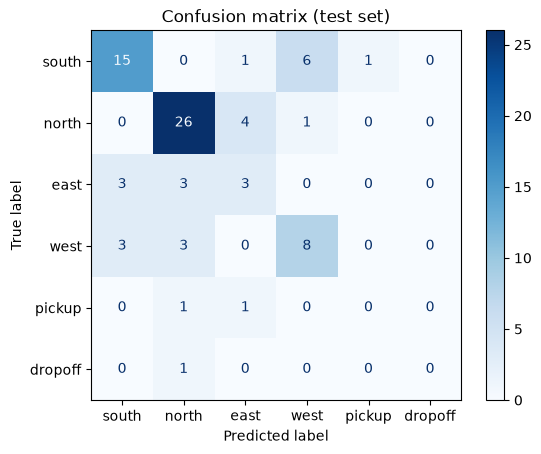

              precision    recall  f1-score   support

       south       0.71      0.65      0.68        23
       north       0.76      0.84      0.80        31
        east       0.33      0.33      0.33         9
        west       0.53      0.57      0.55        14
      pickup       0.00      0.00      0.00         2
     dropoff       0.00      0.00      0.00         1

    accuracy                           0.65        80
   macro avg       0.39      0.40      0.39        80
weighted avg       0.63      0.65      0.64        80

ROC-AUC (average over actions): 0.819231244165853
  south    AUC = 0.889
  north    AUC = 0.913
  east     AUC = 0.912
  west     AUC = 0.821
  pickup   AUC = 0.949
  dropoff  AUC = 0.430
RMSE (probabilities): 0.30411868479023296
RMSE (action numbers): 1.4361406616345072


In [106]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, mean_squared_error)

action_names = ["south", "north", "east", "west", "pickup", "dropoff"]

y_pred = model.predict(X_test)          # the network's answer for each test question
y_prob = model.predict_proba(X_test)    # how confident it is in each of the 6 actions

# 1. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=range(6))
ConfusionMatrixDisplay(cm, display_labels=action_names).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

# 2. Precision, recall, F1 for each action
print(classification_report(y_test, y_pred, labels=range(6),
                            target_names=action_names, zero_division=0))

# 3. ROC-AUC
y_test_onehot = np.eye(6)[y_test]       # the true answers as yes/no columns
print("ROC-AUC (average over actions):",
      roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"))
for i, name in enumerate(action_names):
    print(f"  {name:8s} AUC = {roc_auc_score(y_test_onehot[:, i], y_prob[:, i]):.3f}")

# 4. RMSE (two versions)
print("RMSE (probabilities):", np.sqrt(mean_squared_error(y_test_onehot, y_prob)))
print("RMSE (action numbers):", np.sqrt(mean_squared_error(y_test, y_pred)))

   split  mean_accuracy       std  lowest   highest
0  60/40       0.706250  0.020540  0.6875  0.731250
1  70/30       0.708333  0.030277  0.6500  0.733333
2  80/20       0.760000  0.033912  0.7250  0.812500
3  90/10       0.775000  0.050000  0.7000  0.850000


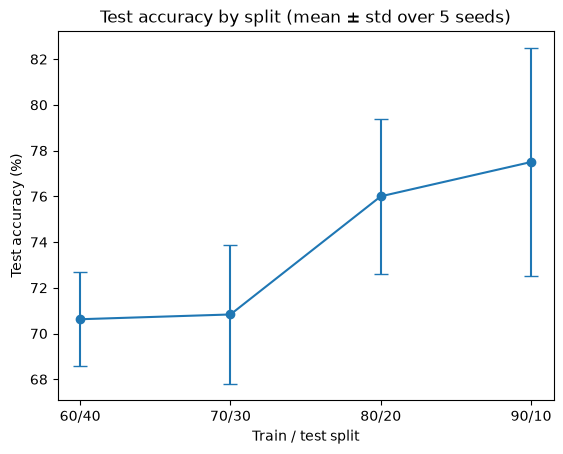

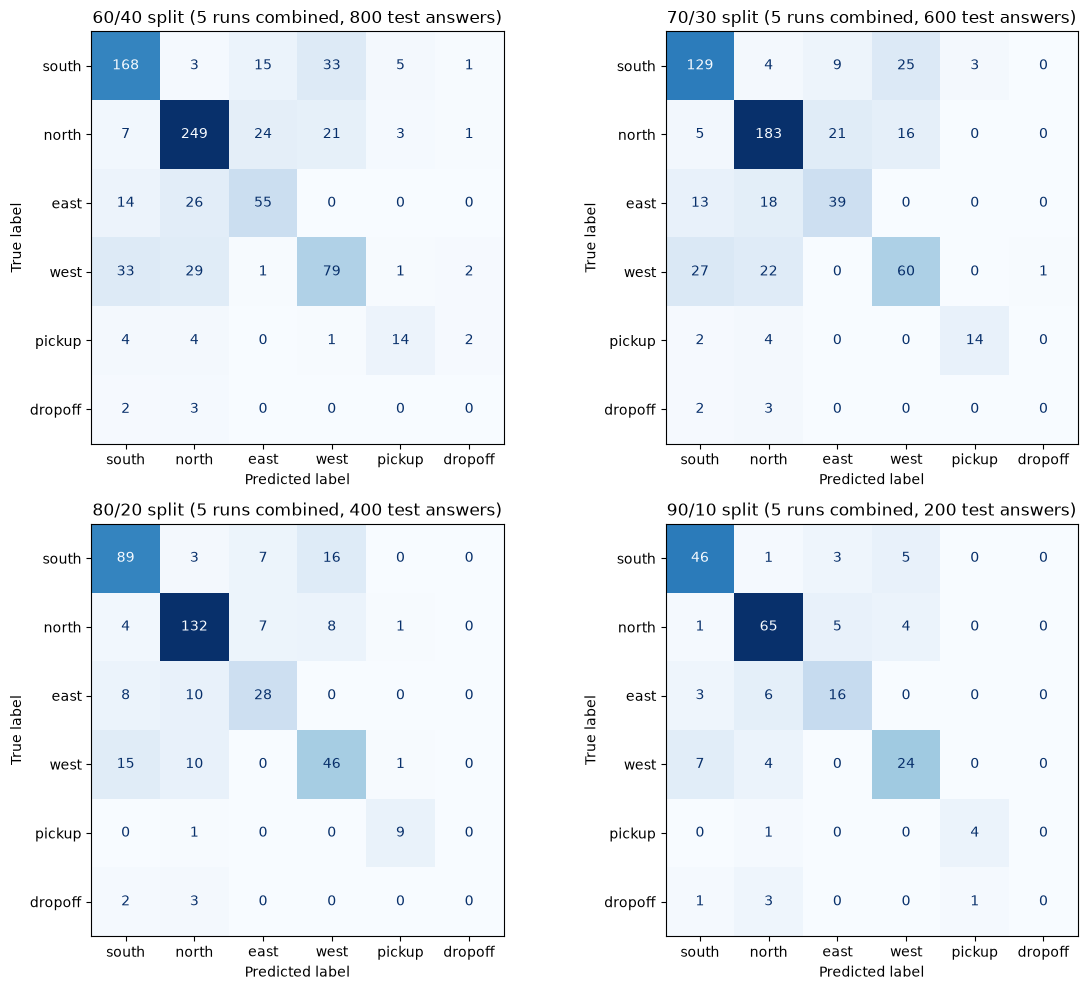

In [107]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

best_settings = dict(hidden_layer_sizes=(200, 100), activation="relu",
                     solver="lbfgs", alpha=0.01, max_iter=3000)

action_names = ["south", "north", "east", "west", "pickup", "dropoff"]

split_results = []
split_cms = {}                                   # one combined confusion matrix per split

for test_size in [0.4, 0.3, 0.2, 0.1]:
    scores = []
    total_cm = np.zeros((6, 6), dtype=int)       # empty 6x6 matrix for this split

    for seed in range(5):                        # 5 different shuffles
        X_train, X_test, y_train, y_test = train_test_split(
            X_onehot, y, test_size=test_size, stratify=y, random_state=seed)

        model = MLPClassifier(random_state=0, **best_settings)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        scores.append(accuracy_score(y_test, y_pred))
        total_cm += confusion_matrix(y_test, y_pred, labels=range(6))   # add this run's matrix

    split_name = f"{round((1 - test_size) * 100)}/{round(test_size * 100)}"
    split_cms[split_name] = total_cm
    split_results.append({
        "split": split_name,
        "mean_accuracy": np.mean(scores),
        "std": np.std(scores),
        "lowest": min(scores),
        "highest": max(scores),
    })

split_df = pd.DataFrame(split_results)
print(split_df)

# chart 1: accuracy by split
plt.errorbar(split_df["split"], split_df["mean_accuracy"] * 100,
             yerr=split_df["std"] * 100, marker="o", capsize=5)
plt.xlabel("Train / test split")
plt.ylabel("Test accuracy (%)")
plt.title("Test accuracy by split (mean ± std over 5 seeds)")
plt.show()

# chart 2: confusion matrix for each split (5 runs added together)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (split_name, cm) in zip(axes.flat, split_cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=action_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{split_name} split (5 runs combined, {cm.sum()} test answers)")
plt.tight_layout()
plt.show()

===== TRAINING data (320 rows) =====
Accuracy: 1.0
ROC-AUC (macro, one-vs-rest): 1.0
RMSE (probabilities): 0.0
RMSE (action numbers): 0.0
              precision    recall  f1-score   support

       south       1.00      1.00      1.00        90
       north       1.00      1.00      1.00       121
        east       1.00      1.00      1.00        38
        west       1.00      1.00      1.00        58
      pickup       1.00      1.00      1.00        10
     dropoff       1.00      1.00      1.00         3

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320

===== TEST (unseen) data (80 rows) =====
Accuracy: 0.713
ROC-AUC (macro, one-vs-rest): 0.897
RMSE (probabilities): 0.285
RMSE (action numbers): 1.23
              precision    recall  f1-score   support

       south       0.84      0.70      0.76        23
       north       0.79      0.87      0.83        31
       

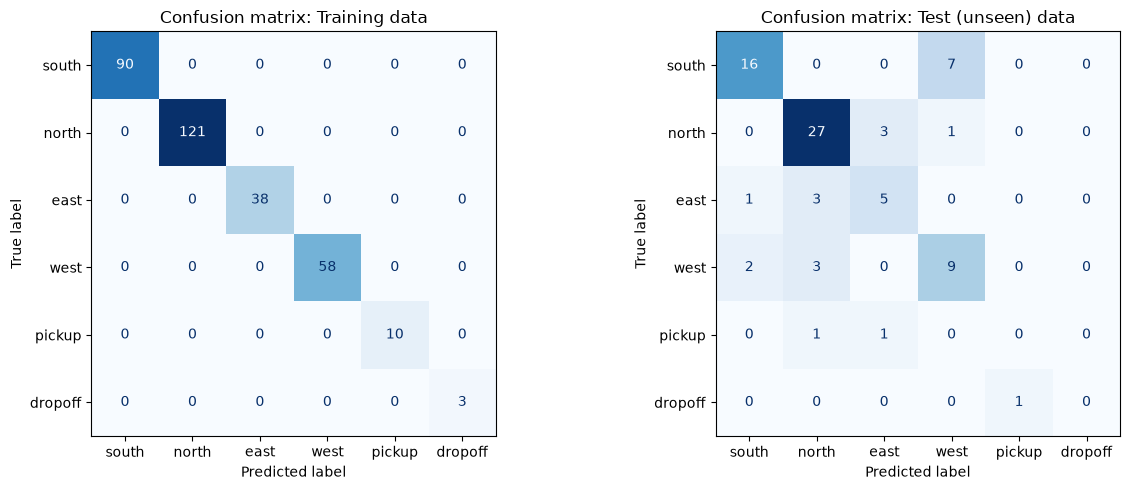

In [108]:
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, mean_squared_error)

# 1. the 80/20 split (rerun here so nothing earlier can overwrite it)
X_train, X_test, y_train, y_test = train_test_split(
    X_onehot, y, test_size=0.2, stratify=y, random_state=0)

# 2. the final network
final_model = MLPClassifier(hidden_layer_sizes=(100, 50), activation="relu",
                            solver="lbfgs", alpha=0.01, max_iter=3000, random_state=0)
final_model.fit(X_train, y_train)

action_names = ["south", "north", "east", "west", "pickup", "dropoff"]

# 3. one function that measures the network on any part of the data
def evaluate(model, X_part, y_part, part_name):
    y_pred = model.predict(X_part)
    y_prob = model.predict_proba(X_part)
    y_true_onehot = np.eye(6)[y_part]

    print(f"===== {part_name} ({len(y_part)} rows) =====")
    print("Accuracy:", round(accuracy_score(y_part, y_pred), 3))
    print("ROC-AUC (macro, one-vs-rest):",
          round(roc_auc_score(y_part, y_prob, multi_class="ovr", average="macro"), 3))
    print("RMSE (probabilities):", round(np.sqrt(mean_squared_error(y_true_onehot, y_prob)), 3))
    print("RMSE (action numbers):", round(np.sqrt(mean_squared_error(y_part, y_pred)), 3))
    print(classification_report(y_part, y_pred, labels=range(6),
                                target_names=action_names, zero_division=0))
    return confusion_matrix(y_part, y_pred, labels=range(6))

# 4. measure it on both sets, as the brief asks
train_cm = evaluate(final_model, X_train, y_train, "TRAINING data")
test_cm = evaluate(final_model, X_test, y_test, "TEST (unseen) data")

# 5. both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, title in zip(axes, [train_cm, test_cm], ["Training data", "Test (unseen) data"]):
    ConfusionMatrixDisplay(cm, display_labels=action_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix: {title}")
plt.tight_layout()
plt.show()

In [109]:
import gymnasium as gym

env = gym.make("Taxi-v4")
u = env.unwrapped

# ---- the two controllers: each looks at the current state and returns an action ----
def network_controller(state):
    # X_onehot already holds the 11 input columns for every reachable state, indexed by state number
    return int(final_model.predict(X_onehot.loc[[state]])[0])

def q_table_controller(state):
    return int(dataset_df_2.loc[state, "best_action"])    # the Q-table's best action, from the CSV

# ---- drive one trip with a controller, from a chosen start state ----
def drive(controller, start_state, max_steps=200):
    env.reset()
    u.s = start_state                  # force this start configuration
    state = start_state
    total_reward = 0
    illegal_moves = 0

    for step in range(1, max_steps + 1):
        action = controller(state)
        state, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        if reward == -10:              # illegal pickup or drop-off
            illegal_moves += 1
        if terminated:                 # passenger delivered
            return {"delivered": True, "steps": step, "reward": total_reward, "illegal": illegal_moves}

    return {"delivered": False, "steps": max_steps, "reward": total_reward, "illegal": illegal_moves}

# ---- all 300 starting configurations ----
start_states = []
for s in range(500):
    taxi_row, taxi_col, pass_idx, dest_idx = u.decode(s)
    if pass_idx < 4 and pass_idx != dest_idx:
        start_states.append(s)
print("Start states:", len(start_states))

rows = []
for s in start_states:
    q = drive(q_table_controller, s)
    n = drive(network_controller, s)
    rows.append({"state": s,
                 "q_delivered": q["delivered"], "q_steps": q["steps"], "q_reward": q["reward"],
                 "nn_delivered": n["delivered"], "nn_steps": n["steps"], "nn_reward": n["reward"],
                 "nn_illegal": n["illegal"]})
drive_df = pd.DataFrame(rows).set_index("state")

delivered = drive_df[drive_df["nn_delivered"]]
failed = drive_df[~drive_df["nn_delivered"]]

print("Q-table delivered:", drive_df["q_delivered"].sum(), "/ 300")
print("Network delivered:", drive_df["nn_delivered"].sum(), "/ 300")
print("Delivered trips as short as the Q-table's:", (delivered["nn_steps"] == delivered["q_steps"]).sum(),
      "/", len(delivered))
print("Average reward  Q-table:", round(drive_df["q_reward"].mean(), 2),
      "| Network:", round(drive_df["nn_reward"].mean(), 2))
print("Failed trips stuck repeating an illegal pickup/drop-off:", (failed["nn_illegal"] > 0).sum())
print("Failed trips stuck moving back and forth:", (failed["nn_illegal"] == 0).sum())

Start states: 300
Q-table delivered: 300 / 300
Network delivered: 138 / 300
Delivered trips as short as the Q-table's: 138 / 138
Average reward  Q-table: 7.93 | Network: -246.95
Failed trips stuck repeating an illegal pickup/drop-off: 25
Failed trips stuck moving back and forth: 137
